# 05 · Modelling

**Goal:** build a model that finds AHU faults and says which type they are, check it the way the maintenance team would, and use it to write `predictions.csv` for July and August.

**How to read this notebook.** It covers five things, one section each:

1. How I framed the problem and why.
2. Features, including the physics.
3. Validation: no leakage across time or across machines, and a metric the technicians care about.
4. Results and error analysis.
5. A new AHU with no history, and a building with fewer sensors.

Then the predictions for the test period and a summary. All the logic is in `src/ahu_fdd/` with unit tests; this notebook runs it and explains the choices. More detail in `docs/04 - Modelling.md`.

**Run time: about 5 to 7 minutes.** Most of it is training the models of every comparison (each option trains three LightGBM models, one per validation block). The outputs are saved, so the notebook can be read without running it.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from ahu_fdd.config import FAULT_NAMES, FOLDS, SEED
from ahu_fdd.data import (
    add_building,
    add_extra_labels,
    clean_sensors,
    label_rows,
    load_labels,
    load_sensors,
)
from ahu_fdd.evaluation import cross_validate as run_blocks
from ahu_fdd.evaluation import month_folds, rows_to_events, score_events
from ahu_fdd.features import MODEL_FEATURES, OTHER_FEATURES, add_features
from ahu_fdd.models import build_lgbm, fit_model, training_rows
from ahu_fdd.plots import FAULT_COLORS, save_fig, set_style
from ahu_fdd.predict import rules_predict, train_and_predict, with_deviations

set_style()  # same look for every chart

In [2]:
# Cleaned train data with labels (28 work orders + the stuck flap found in notebook 04)
labels = add_extra_labels(load_labels())
train = add_building(clean_sensors(load_sensors("train")))
train["label"] = label_rows(train, labels)
feats = add_features(train)  # physics signals, smoothed (src/ahu_fdd/features.py)
print(f"{len(labels)} events, {len(feats):,} rows")

29 events, 2,050,081 rows


## 1. How I framed the problem

**The question per row:** for each machine and each 5-minute row with the fan on, is it normal or one of the four faults? That is a classification with five classes. But nobody acts on rows: a maintenance team acts on **alarms**, the way a technician lives them. So the output of the model goes through a post-processing step that turns rows into alarms.

There are several ways to frame it. What I considered:

| Framing | For | Against | Used? |
|---|---|---|---|
| Physics rules | No examples needed, easy to explain, follows notebook 04 | Fixed thresholds, more false alarms | Yes: baseline, fault type, and new machines |
| Model of normal behaviour + residuals | Learns from healthy data only | Says "something is odd", not which fault; I need the type too | Partly: every feature is a residual against the machine's own normal |
| Supervised classifier | Learns the thresholds and the combinations of signals | Only 29 events to learn from | Yes: decides if there is an alarm |

**My choice: a combination.** The features are residuals against each machine's normal (from the second framing). A LightGBM classifier decides **if** there is a fault, because it gives the fewest false alarms. The physics rules decide **which** fault, because they get the type right more often. Section 4 shows the numbers behind this choice.

**Why LightGBM and not another model:**
- The problem is tabular and threshold-like ("supply air 2.5 °C off *and* valve at 100%"): gradient boosted trees learn exactly this.
- It handles empty values on its own: no CO2 in the mall, no check at rest on 24/7 machines, the frozen sensor in test.
- Class weights handle the imbalance without inventing rows.
- It is fast on 2 million rows and I can explain each alarm (feature importance).
- With only 29 events, the model matters less than the features. I keep it small (shallow trees, many rows per leaf) so it doesn't learn the 29 events by heart, and I compare it with simpler options in section 4.

## 2. Features and physics

Each feature comes from the fingerprint of a fault (notebook 04) and is compared with **the same machine's own normal**, because notebook 03 showed machines differ a lot. The full explanation, grouped by fault, is in `docs/04 - Modelling.md`. In short:

In [3]:
# The 9 features of the model and the fault each one is mainly for
feature_use = {
    "sat_error_dev": "stuck tap: supply air off target vs this machine's normal",
    "valve_dev": "stuck tap: valve more open than this machine's normal",
    "valve_at_limit_1h": "stuck tap: share of the last hour with the valve command at 0% or 100%",
    "valve_excess": "weak radiator: valve above what this machine needs for the same work",
    "oa_fraction_1h": "stuck flap: share of outdoor air in the mix (mixing formula)",
    "oa_fraction_dev": "stuck flap: outdoor air vs this machine's normal",
    "damper_dev": "stuck flap: flap command above normal (the controller compensates)",
    "co2_dev": "stuck flap: CO2 above normal (office and hospital only)",
    "rest_offset_dev": "lying thermometer: last check with the fan off, vs normal",
}
assert list(feature_use) == MODEL_FEATURES
pd.Series(feature_use, name="what it is for").to_frame()

,what it is for
sat_error_dev,stuck tap: supply air off target vs this machi...
valve_dev,stuck tap: valve more open than this machine's...
valve_at_limit_1h,stuck tap: share of the last hour with the val...
valve_excess,weak radiator: valve above what this machine n...
oa_fraction_1h,stuck flap: share of outdoor air in the mix (m...
oa_fraction_dev,stuck flap: outdoor air vs this machine's normal
damper_dev,stuck flap: flap command above normal (the con...
co2_dev,stuck flap: CO2 above normal (office and hospi...
rest_offset_dev,lying thermometer: last check with the fan off...


**Physics used:**
- **Mixing formula:** outdoor air share = (MAT − RAT) / (OAT − RAT). A stuck flap drives it to 0.
- **Cooling work:** fan speed share × (MAT − SAT). A weak radiator needs more valve for the same work (`valve_excess`). Comparing with one fixed value instead gave 4.7 false alarms per machine per month, because a valve is not linear.
- **Check at rest:** with the fan off for an hour, the supply and mixed air sensors should agree. A lying thermometer is invisible while the machine runs (the controller trusts it), but shows here.

**Why only relative features:** I also tried giving the model the raw values (supply air error, valve opening, outside temperature, fan speed...). With them, the model called the faults of the three machines that are always at their limit wrong more often: their raw values always look like a stuck tap. Right type with raw values: 69%; with relative values only: 86% (test A in section 4).

## 3. Validation

**Against leakage across time:** three blocks of about two months (`FOLDS` in `config.py`). Each block is predicted by a model trained on the other two. The cuts fall on days with no labelled event in progress, so no fault is half in training and half in validation. Each machine's normal is computed only from the training blocks.

**Against leakage across machines:** within the three blocks the same 40 machines appear in training and validation (like in real life, where each machine has its history). Section 5 adds the harder test: a whole building the model has never seen.

**A metric the technicians care about:** `score_events()` in `src/ahu_fdd/evaluation.py` scores by event: is each fault found, how fast, is the type right, and how many false alarms per machine per month. Row accuracy would be useless: always saying "normal" is right on 97.6% of rows.

In [4]:
# Run any prediction function on the three blocks and score it by event
folds = month_folds(feats["timestamp"], list(FOLDS))  # also used for the error analysis


def cross_validate(predict):
    # cross_validate() in src/ahu_fdd/evaluation.py, always on the same data and blocks
    return run_blocks(feats, labels, predict)


def score_line(result):
    return {
        "alarms raised": result.get("alarms"),
        "detected": f"{result['detected']:.0%}",
        "right type": f"{result['type_right']:.0%}",
        "median delay (h)": round(result["median_delay_h"], 1),
        "false alarms": result["false_alarms"],
        "false alarms per AHU per month": round(result["false_alarms_per_ahu_month"], 2),
    }

## 4. Results

**How:** the same validation and the same post-processing for every option. Rules first (the baseline any model must beat), then three classifiers on the same 9 features, then the combination.

In [5]:
# Every option, scored the same way (takes about a minute)
def model_only(make_model):
    return lambda tr, va: train_and_predict(tr, va, model=make_model(), rule_types=False)


options = {
    "physics rules": rules_predict,
    "logistic regression": model_only(
        lambda: make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
            LogisticRegression(class_weight="balanced", max_iter=2000),
        )
    ),
    "random forest": model_only(
        lambda: RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=200,
            class_weight="balanced",
            n_jobs=-1,
            random_state=SEED,
        )
    ),
    "LightGBM": model_only(build_lgbm),
    "LightGBM + rule types (final)": train_and_predict,
}
results = {name: cross_validate(predict) for name, predict in options.items()}
pd.DataFrame({name: score_line(r) for name, r in results.items()}).T

,alarms raised,detected,right type,median delay (h),false alarms,false alarms per AHU per month
physics rules,79,100%,93%,11.2,42,0.18
logistic regression,387,76%,59%,4.3,352,1.48
random forest,51,93%,79%,11.2,8,0.03
LightGBM,52,100%,86%,9.8,11,0.05
LightGBM + rule types (final),52,100%,93%,9.8,11,0.05


**How to read it:** 29 events over the three blocks, about 240 machine-months.
- **Physics rules:** find every fault and get most types right, but give more false alarms.
- **Logistic regression:** much worse. It can't combine signals ("error *and* valve at a limit") and it misses faults.
- **Random forest:** few false alarms, but it misses faults and gets fewer types right than LightGBM.
- **LightGBM:** finds every fault with very few false alarms, but gets fewer types right than the rules.
- **LightGBM + rule types:** LightGBM decides *if* there is an alarm, the rules decide *which* fault. It keeps the best of both: every fault found, the type of the rules, the false alarms of LightGBM.

**Decision:** the final model is LightGBM + rule types.

### What I tried before this result

The final settings come from three tests, re-run here so every choice has its numbers. All three use the same validation and scorer as above.

**Test A: which features does the model get?** First I gave the model every signal, raw values included (outside air, fan speed, supply air error, valve opening...). Then only the signals compared with each machine's own normal. I compare the model alone (no rule types), to see what the model itself gets right.

In [6]:
# Test A: all signals vs only the relative ones (model alone, to see its own fault types)
feature_sets = {
    "all signals (raw + relative)": OTHER_FEATURES + MODEL_FEATURES,
    "relative signals only (final)": MODEL_FEATURES,
}
test_a = {
    name: cross_validate(
        lambda tr, va, f=features: train_and_predict(tr, va, features=f, rule_types=False)
    )
    for name, features in feature_sets.items()
}
pd.DataFrame({name: score_line(r) for name, r in test_a.items()}).T

,alarms raised,detected,right type,median delay (h),false alarms,false alarms per AHU per month
all signals (raw + relative),50,90%,69%,7.7,10,0.04
relative signals only (final),52,100%,86%,9.8,11,0.05


**How to read it:** with every signal, the model finds fewer faults and gets fewer types right. The raw values of the three machines that are always at their limit look like a stuck tap all the time, so the model learns "valve at 100% = stuck tap". Comparing each machine with its own normal removes that. **Decision:** the model only sees relative signals.

**Test B: how sure must the model be before a row counts as a fault?** A low threshold finds faults earlier but raises more alarms; a high one is quieter but can miss faults.

In [7]:
# Test B: confidence threshold of the final pipeline
test_b = {
    f"sure at {p:.0%}+": cross_validate(lambda tr, va, p=p: train_and_predict(tr, va, min_prob=p))
    for p in [0.5, 0.7, 0.8, 0.9]
}
pd.DataFrame({name: score_line(r) for name, r in test_b.items()}).T

,alarms raised,detected,right type,median delay (h),false alarms,false alarms per AHU per month
sure at 50%+,128,100%,93%,5.8,86,0.36
sure at 70%+,67,100%,93%,9.1,25,0.11
sure at 80%+,52,100%,93%,9.8,11,0.05
sure at 90%+,38,93%,86%,13.3,3,0.01


**How to read it:** going from 50% to 80% cuts the false alarms a lot and still finds every fault. At 90% the model starts to miss faults. **Decision:** 80% (`ALARM_MIN_PROB` in `config.py`), the highest threshold that still finds all 29.

**Test C: join the pieces of one fault?** Every morning the first 30 minutes after a start have no alarms, so a fault that lasts days was cut into one alarm per day. For a technician that is one fault, one work order.

In [8]:
# Test C: join alarms of one machine split by a short gap of running time
gaps = {"not joined": 0, "joined if under 2 h apart": 24, "joined if under 6 h apart (final)": 72}
test_c = {
    name: cross_validate(lambda tr, va, g=rows: train_and_predict(tr, va, max_gap_rows=g))
    for name, rows in gaps.items()
}
pd.DataFrame({name: score_line(r) for name, r in test_c.items()}).T

,alarms raised,detected,right type,median delay (h),false alarms,false alarms per AHU per month
not joined,193,100%,93%,9.8,13,0.05
joined if under 2 h apart,70,100%,93%,9.8,11,0.05
joined if under 6 h apart (final),52,100%,93%,9.8,11,0.05


**How to read it:** `alarms raised` counts every alarm, true or false. Joining the pieces of one fault cuts the number of alarms, and it can never add false alarms: it only joins alarms that are already there. Finding and type stay the same. **Decision:** join pieces up to 6 hours of running apart (`MAX_GAP_ROWS`). On the test period this took the alarms from 68 to 14.

A fourth test is in section 5: to help the model with buildings that have no CO2 sensor, I trained it with CO2 hidden in half of the rows. It did not help, so I left it out.

In [9]:
# Final model: result per fault type and per building
final = results["LightGBM + rule types (final)"]["per_event"]
final["building"] = final["ahu_id"].str[:2]
by_type = final.groupby("fault_type")[["detected", "type_right"]].mean()
by_type.index = [f"{FAULT_NAMES[f]} ({f})" for f in by_type.index]
by_type.map("{:.0%}".format)

,detected,type_right
stuck tap (chw_valve_stuck),100%,100%
weak radiator (low_coil_capacity),100%,71%
stuck flap (oa_damper_stuck),100%,100%
lying thermometer (sat_sensor_bias),100%,100%


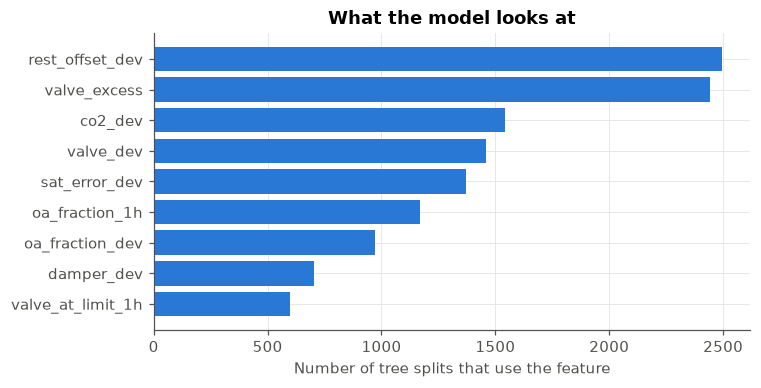

In [10]:
# Which features LightGBM uses most (trained on all of January to June)
all_train, _ = with_deviations(feats, feats.iloc[:0])
full_model = fit_model(build_lgbm(), training_rows(all_train))
importance = pd.Series(full_model.feature_importances_, MODEL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance.index, importance.values, color="#2a78d6")
ax.set_xlabel("Number of tree splits that use the feature")
ax.set_title("What the model looks at")
save_fig(fig, "05_feature_importance")
plt.show()

**How to read it:** longer bar = the model uses that feature in more decisions. The check at rest (lying thermometer) and the valve excess (weak radiator) are at the top: the two faults that need physics to be seen at all. Every feature is used, so each fault has its own signal.

### Error analysis: where it fails and what would fix it

In [11]:
# Faults with the wrong type, and the false alarms of the final model
wrong = final[~final["type_right"]].copy()
wrong["plain_name"] = wrong["fault_type"].map(FAULT_NAMES)
wrong[["ahu_id", "plain_name", "fault_type", "predicted_type", "delay_h"]].round(1)

,ahu_id,plain_name,fault_type,predicted_type,delay_h
8,B1-AHU-05,weak radiator,low_coil_capacity,chw_valve_stuck,41.1
12,B3-AHU-02,weak radiator,low_coil_capacity,chw_valve_stuck,18.2


**Wrong types:** only the weak radiators of B1-AHU-05 and B3-AHU-02, called stuck tap. These are two of the three machines that are always at their limit (notebook 03): their valve is at 100% on a normal day, so when the coil gets weak the valve can't open more, and the only sign left is warm supply air, which is also the sign of a stuck tap. **What would fix it:** the actual valve position (not only the command) or a chilled water flow meter. With those, a stuck tap (valve not moving) and a weak coil (valve moving, little cooling) are easy to tell apart.

In [12]:
# False alarms of the final model: which machines and how long
def false_alarms(predict):
    rows = []
    for in_block in folds:
        block = feats[in_block].assign(pred=predict(feats[~in_block], feats[in_block]).values)
        for alarm in rows_to_events(block).itertuples():
            true = labels[labels["ahu_id"] == alarm.ahu_id]
            if not ((true["start"] <= alarm.end) & (true["end"] > alarm.start)).any():
                rows.append(alarm._asdict())
    return pd.DataFrame(rows)


fa = false_alarms(train_and_predict)
fa["hours_running"] = (fa["rows"] * 5 / 60).round(1)
fa["plain_name"] = fa["fault_type"].map(FAULT_NAMES)
fa[["ahu_id", "plain_name", "start", "hours_running"]]

,ahu_id,plain_name,start,hours_running
0,B3-AHU-02,weak radiator,2025-01-14 15:50:00,3.3
1,B3-AHU-02,weak radiator,2025-02-08 13:40:00,4.9
2,B3-AHU-09,weak radiator,2025-02-08 14:15:00,3.3
3,B3-AHU-09,weak radiator,2025-02-24 15:55:00,2.1
4,B3-AHU-07,lying thermometer,2025-03-06 18:25:00,2.8
5,B3-AHU-07,lying thermometer,2025-03-22 12:50:00,3.1
6,B3-AHU-08,lying thermometer,2025-03-17 19:10:00,3.8
7,B3-AHU-01,lying thermometer,2025-05-20 12:10:00,3.2
8,B3-AHU-10,lying thermometer,2025-05-15 12:00:00,2.6
9,B3-AHU-11,lying thermometer,2025-05-30 17:05:00,2.6


**False alarms:** about one per machine every 20 months. All of them are in the mall, and all are short: 2 to 5 hours of running. Four are weak radiators on B3-AHU-02 and B3-AHU-09, two of the machines always at their limit, where a hot afternoon pushes the valve beyond its usual need. The rest are lying thermometer alarms of a few hours. **What would fix it:** a longer minimum alarm for the faults that can't do harm in a few hours (a lying thermometer or a weak radiator could wait 6 hours), and feedback from the technicians ("no fault found") as labels, so the model learns from its own false alarms.

## 5. A new AHU with no history, and a building with fewer sensors

**How:** I hide a whole building. The model is trained on the other two. The hidden building has **no labels**: its normal (baselines and valve curve) comes from its **first two weeks of data**, all treated as healthy, which is what I would have on a newly installed machine. Then I score its faults after those two weeks. The mall (B3) is also the building with fewer sensors: no CO2 and no airflow.

In [13]:
# Leave one building out, with a two-week warm-up for its normal
warm_up_end = feats["timestamp"].min() + pd.Timedelta("14D")
rows = {}
for building in ["B1", "B2", "B3"]:
    seen, new = feats[feats["building"] != building], feats[feats["building"] == building]
    first_weeks, later = new[new["timestamp"] < warm_up_end], new[new["timestamp"] >= warm_up_end]
    new_labels = labels[(labels["ahu_id"].str[:2] == building) & (labels["start"] >= warm_up_end)]
    for name, predict in [("physics rules", rules_predict), ("final model", train_and_predict)]:
        pred = predict(seen, later, target_normal=first_weeks)
        result = score_events(later.assign(pred=pred.values), new_labels)
        line = score_line(result) | {"events": result["events"]}
        line.pop("alarms raised")  # only counted when running the three blocks
        rows[(building, name)] = line
pd.DataFrame(rows).T

detected right type median delay (h) false alarms  \
B1 physics rules     100%        89%             17.5            2   
   final model       100%        89%              0.7            4   
B2 physics rules     100%       100%              9.7            1   
   final model        50%        50%              1.3            0   
B3 physics rules     100%        92%             11.2           38   
   final model        58%        50%              9.9           73   

                 false alarms per AHU per month events  
B1 physics rules                           0.02      9  
   final model                             0.05      9  
B2 physics rules                           0.02      4  
   final model                              0.0      4  
B3 physics rules                           0.58     12  
   final model                             1.11     12

**How to read it:** each pair of lines is one building that the model never saw, with only two weeks of unlabelled data to learn its normal.

- **Office (B1):** both work well.
- **Hospital (B2):** the model misses half of the faults (two weak radiators). It learned weak radiators mostly from office and mall machines, which work very differently from the 24/7 hospital machines. The rules find all of them.
- **Mall (B3), the building with fewer sensors:** the model misses several faults and raises more false alarms. Two reasons: the model learned the stuck flap mostly through CO2, which the mall doesn't have, and 5 of the 6 lying thermometers are in the mall, so without it the model has one example to learn from. The rules don't need examples, only physics, and find every fault.

**Decision, for a new AHU or building:**
1. **Weeks 1-2:** collect data, no alarms. Learn each machine's normal (baselines and valve curve).
2. **From week 3:** physics rules only. They need no labelled faults and work with the sensors the building has (no CO2: the stuck flap still shows in the outdoor air share).
3. **When the building has its own confirmed work orders** (from the technicians' feedback): switch to the model, retrained with them.

For **fewer sensors**, the features are allowed to be empty and the rules don't depend on the missing ones. A model trained with CO2 doesn't transfer well to a building without it (I also tried hiding CO2 in half the training rows; it didn't help). With more buildings, I would train one model per sensor set.

## 6. Predictions for July and August

**How:** `python -m ahu_fdd.predict` trains on all of January to June and predicts the test period. It writes one row per row of `ahu_test.parquet`, and `format_problems()` checks its format. It also saves the trained model and its model card (code version and commit, training data, settings, validation scores) in `artifacts/lgbm-v<version>/`, so every `predictions.csv` can be traced back to the model that made it. Here I look at the alarms it raises.

In [14]:
# Alarms in the test period, from the file written by python -m ahu_fdd.predict
pred = pd.read_csv("../../predictions.csv", parse_dates=["timestamp"])
test = load_sensors("test")[["ahu_id", "timestamp", "fan_status"]]
test_alarms = rows_to_events(test.merge(pred, on=["ahu_id", "timestamp"]), "fault_type")
test_alarms["days"] = ((test_alarms["end"] - test_alarms["start"]) / pd.Timedelta("1D")).round(1)
test_alarms["plain_name"] = test_alarms["fault_type"].map(FAULT_NAMES)
print(f"{len(test_alarms)} alarms in 40 machines over 2 months")
test_alarms[["ahu_id", "plain_name", "start", "end", "days"]].sort_values("start")

14 alarms in 40 machines over 2 months


,ahu_id,plain_name,start,end,days
13,B3-AHU-11,lying thermometer,2025-07-02 13:05:00,2025-07-02 16:50:00,0.2
0,B1-AHU-01,stuck tap,2025-07-07 15:15:00,2025-07-11 19:25:00,4.2
1,B1-AHU-03,weak radiator,2025-07-09 14:15:00,2025-07-11 19:25:00,2.2
10,B3-AHU-05,lying thermometer,2025-07-12 10:30:00,2025-07-12 12:35:00,0.1
6,B2-AHU-12,stuck flap,2025-07-12 16:40:00,2025-07-24 15:25:00,11.9
2,B1-AHU-09,weak radiator,2025-07-15 09:05:00,2025-07-18 11:25:00,3.1
3,B1-AHU-12,lying thermometer,2025-07-22 08:05:00,2025-08-06 19:25:00,15.5
11,B3-AHU-05,stuck tap,2025-07-22 09:45:00,2025-07-29 22:55:00,7.5
4,B1-AHU-16,stuck tap,2025-07-23 09:30:00,2025-07-28 17:30:00,5.3
12,B3-AHU-06,lying thermometer,2025-07-25 09:30:00,2025-08-11 20:40:00,17.5


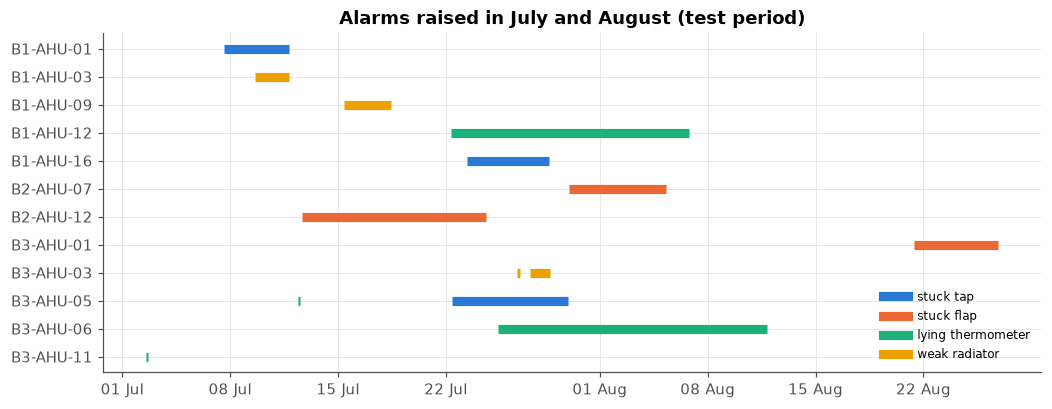

In [15]:
# Timeline of the test alarms, one line per machine with an alarm
fig, ax = plt.subplots(figsize=(11, 4))
machines = sorted(test_alarms["ahu_id"].unique(), reverse=True)
for alarm in test_alarms.itertuples():
    y = machines.index(alarm.ahu_id)
    ax.plot(
        [alarm.start, alarm.end],
        [y, y],
        lw=6,
        color=FAULT_COLORS[alarm.fault_type],
        solid_capstyle="butt",
    )
ax.set_yticks(range(len(machines)), machines)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
handles = [
    plt.Line2D([], [], color=FAULT_COLORS[f], lw=6, label=FAULT_NAMES[f]) for f in FAULT_NAMES
]
ax.legend(handles=handles, loc="lower right", fontsize=8)
ax.set_title("Alarms raised in July and August (test period)")
save_fig(fig, "05_test_alarms")
plt.show()

**How to read it:** one line per machine with at least one alarm, coloured by fault type, from the first to the last hour of each alarm.

**Sanity checks** (not labels, the test labels are hidden):
- The eight candidate faults I saw in notebook 04 by looking at the fingerprints are all here, with the same type and dates: stuck taps on B1-AHU-01, B1-AHU-16 and B3-AHU-05; stuck flaps on B2-AHU-07, B2-AHU-12 and B3-AHU-01; lying thermometers on B1-AHU-12 and B3-AHU-06.
- The model also raises two weak radiators I could not look for by hand (B1-AHU-03 and B1-AHU-09, a few days each in July).
- **B2-AHU-08**, whose supply air sensor is frozen for 9 days in test (notebook 02), has no alarm: the frozen readings were set to empty and the model doesn't treat a missing sensor as a fault.
- Most of the other alarms are short (hours), similar to the false alarms seen in validation.

## Summary

**The idea.** What counts is alarms, not rows, so I built my own event-level scorer first and judged every choice with it.

1. **Framing: a combination.** What happens: LightGBM decides if there is a fault, the physics rules decide which one. Everyday example: a nurse who takes your temperature decides *if* you see the doctor; the doctor decides *what* you have. Why it matters: LightGBM gives the fewest false alarms, the rules get the type right more often. Decision: final model = LightGBM + rule types.
2. **Features: residuals against each machine's own normal.** What happens: every feature says how far a machine is from its own usual behaviour, built from the physics of each fault. Why it matters: with raw values, the three machines always at their limit were mixed up. Decision: 9 relative features only.
3. **Validation without leakage.** What happens: three blocks of two months, cut where no fault is in progress, each machine's normal from training data only, and a whole building hidden to test new machines. Decision: every number in this notebook comes from data the model didn't see.
4. **Results.** 29 faults found out of 29, 93% with the right type, about 10 hours median delay, 0.05 false alarms per machine per month (about one per machine every 20 months). The only wrong types are two weak radiators on machines always at their limit; a valve position sensor or a water flow meter would fix them.
5. **New machines and fewer sensors.** What happens: a model trained on other buildings misses faults in a building it never saw, especially one without CO2. The rules find them all. Decision: new machines start with two weeks of learning their normal, then the rules, and move to the model once they have their own confirmed work orders.
6. **Test period.** 14 alarms in 40 machines over two months, including the eight candidates from notebook 04, and none on the machine with the frozen sensor.

**In one sentence:** a small LightGBM decides if a machine needs a visit and the physics rules say why, which finds every fault in validation with about one false alarm per machine every 20 months, and new buildings start with the rules alone until they have their own history.

**If I had more time:** tune and compare XGBoost and CatBoost, a two-step model (fault yes/no, then which one), use the unlabelled data (self-training on confident alarms), and ask the operator for the technicians' "no fault found" outcomes to measure false alarms on real visits.